# W7 Lab A — From Likelihood to Neural Prediction

**October 13, 2026 · CPU · no manual upload, API key or GPU.** Save a copy in Drive and run from the top. This notebook runs independently of the other lab. If setup asks for a runtime restart after installing packages, restart once and run all again.

[Main note](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/course/notion/w7/w7-predictive-models.md) · [Worked calculations](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/course/notion/w7/w7-worked-calculations.md) · [Worksheet](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/course/notion/w7/w7-experiment-record.md) · [API guide](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/course/notion/w7/w7-code-guide.md)

Predict before running. Unfinished exercise cells do not block the demonstrations. Fixed code references and hashes make the imported implementation inspectable. Code links name the exact definitions used here.


In [ ]:
import sys, subprocess, importlib.metadata, hashlib, urllib.request, time
from pathlib import Path

PINS = {"numpy":"2.2.6", "matplotlib":"3.10.3", "scipy":"1.16.3",
        "pandas":"2.3.3", "gradio":"6.27.0"}
missing = []
for package, version in PINS.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f"{package}=={version}")
restart = [p for p,v in PINS.items() if p in sys.modules and getattr(sys.modules[p], "__version__", v) != v]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
if restart:
    raise RuntimeError("Packages updated. Use Runtime > Restart session, then Run all. Loaded old packages: "+", ".join(restart))

CODE_REF = "2026-fall-w7"
EXPECTED = {'advml_predictive.py': 'beaa85083c3f1cc4ead5f253ff11c82b7f71dc3ad2da8fc21d7307505e20583b', 'advml_predictive_app.py': 'aa0fd860bdddfef37fab03578b342de381744237771d81b72fd65288fa93cec9'}
local = Path.cwd() / "src"
local_ok = all((local/name).is_file() and hashlib.sha256((local/name).read_bytes()).hexdigest()==digest
               for name,digest in EXPECTED.items())
support = local if local_ok else Path.cwd() / "w7_support" / CODE_REF
support.mkdir(parents=True, exist_ok=True)
downloaded = []
for name,digest in EXPECTED.items():
    path = support/name
    if path.is_file() and hashlib.sha256(path.read_bytes()).hexdigest()==digest:
        continue
    url = f"https://raw.githubusercontent.com/lunalab-ai/advML/{CODE_REF}/src/{name}"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(url, timeout=40) as response:
                payload = response.read()
            break
        except (OSError, TimeoutError):
            if attempt == 2:
                raise
            time.sleep(attempt+1)
    if hashlib.sha256(payload).hexdigest()!=digest:
        raise RuntimeError(f"Source hash mismatch: {name}. Do not run unverified code.")
    temporary = path.with_suffix(".download")
    temporary.write_bytes(payload)
    temporary.replace(path)
    downloaded.append(name)
sys.path.insert(0, str(support.resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr
from IPython.display import display
print({"Python":sys.version.split()[0], "code_ref":CODE_REF, "downloaded":downloaded,
       "cache_or_reviewed_local":not downloaded, "versions":PINS})


## 1. A Gaussian loss you can audit

[gaussian_nll: definition](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/src/advml_predictive.py#L45) · [bernoulli_nll: definition](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/src/advml_predictive.py#L52) · [poisson_nll: definition](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/src/advml_predictive.py#L59)

The NLL functions return sums. Gaussian NLL accepts **variance**, not standard deviation. The formula includes the normalization term. First inspect each residual, then compare the manual expression with the function.

$$L=\frac n2\log(2\pi\sigma^2)+\frac{\sum_i(y_i-\mu_i)^2}{2\sigma^2}.$$


In [ ]:
from advml_predictive import (gaussian_nll, bernoulli_nll, poisson_nll,
    make_data, TinyMLP, prior_nn_functions)
from scipy.special import expit
y=np.array([1.,2.]);mu=np.array([1.5,1.5]);variance=1.
errors=y-mu
manual=len(y)/2*np.log(2*np.pi*variance)+(errors@errors)/(2*variance)
display(pd.DataFrame({'observed':y,'mean':mu,'residual':errors,'squared_error':errors**2}))
print({'SSE':errors@errors,'MSE':np.mean(errors**2),'manual_sum_NLL':manual,
       'function_sum_NLL':gaussian_nll(y,mu,variance)})


### A1 — Your turn

For observations [0,2], candidate means [1,1] and noise SD 2, calculate SSE, MSE and summed Gaussian NLL. Identify what to pass to the variance argument. Explain why these three values differ.


In [ ]:
a1_response = ""  # Response field for A1; later demonstrations remain runnable.


## 2. The observed label selects the likelihood contribution

For label 1 use p; for label 0 use 1-p. Probabilities belong to separate cases. The helper accepts logits and computes a numerically stable loss; it does not threshold probabilities.


In [ ]:
labels=np.array([1,0]);probabilities=np.array([.8,.25])
logits=np.log(probabilities/(1-probabilities))
chosen=np.where(labels==1,probabilities,1-probabilities)
display(pd.DataFrame({'label':labels,'P(label=1)':probabilities,'selected_probability':chosen,'NLL_contribution':-np.log(chosen)}))
print({'joint_probability':chosen.prod(),'sum_NLL':bernoulli_nll(labels,logits),
       'mean_NLL':bernoulli_nll(labels,logits)/len(labels)})


### A2 — Your turn

A classmate uses `bad_loss = -np.log(probabilities).sum()` for every binary dataset. Explain the error and repair it for labels [0,1] and probabilities [.2,.7]. Also explain why the two probabilities need not sum to one.


In [ ]:
a2_response = ""  # Response field for A2; later demonstrations remain runnable.


## 3. Change the output family, keep the real-valued score

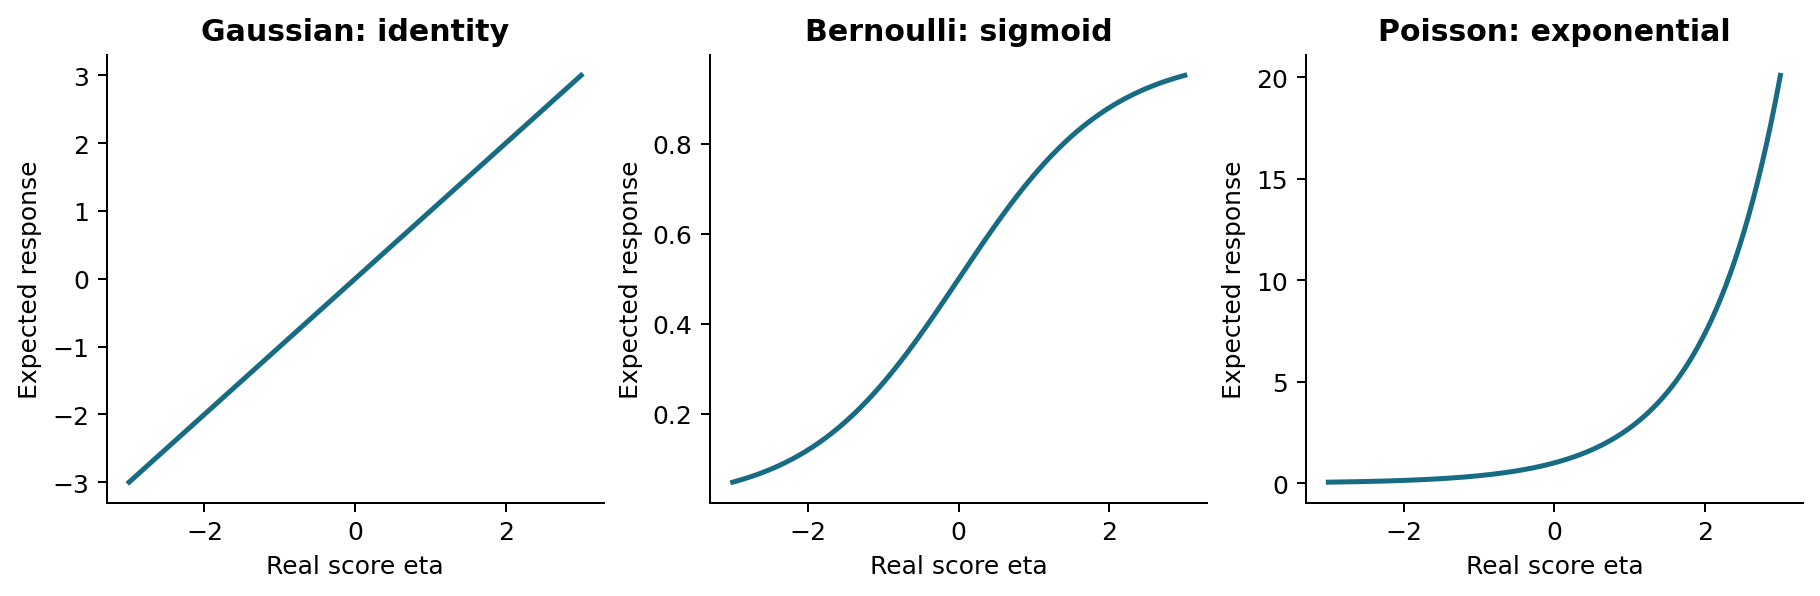

A Gaussian mean is unrestricted. A Bernoulli mean is a probability. A Poisson mean is a positive expected count, not necessarily an integer. The observation must still belong to the distribution’s support.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/advML/2026-fall-w7/course/notion/w7/assets/03-links.png)


In [ ]:
scores=np.array([-1.,0.,1.])
display(pd.DataFrame({'score':scores,'Gaussian mean':scores,
                     'Bernoulli mean':expit(scores),'Poisson mean':np.exp(scores)}))
print('Poisson y=3, log-rate=log(2):',poisson_nll([3],[np.log(2)]))
try:
    poisson_nll([.5],[0])
except ValueError as exc:
    print('Expected support check:',exc)


### A3 — Your turn

Fill the conceptual blanks: Bernoulli mean = ___(eta); Poisson mean = ___(eta). At eta=0, calculate both means. Is an observed Poisson value 0.5 valid? Explain the difference between a response and its expectation. Then give one reason to consider partial pooling across small groups.


In [ ]:
a3_response = ""  # Response field for A3; later demonstrations remain runnable.


## 4. A fitted neural predictor

[make_data: definition](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/src/advml_predictive.py#L26) · [TinyMLP: definition](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/src/advml_predictive.py#L141) · [TinyMLP.fit: definition](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/src/advml_predictive.py#L165) · [TinyMLP.features: definition](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/src/advml_predictive.py#L181) · [TinyMLP.predict: definition](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/src/advml_predictive.py#L187)

The synthetic training data have a gap and a limited input range. The model sees training x and y only. The true function and independently noisy test responses are used after fitting. The small tanh network is point-estimated by L-BFGS. Read its convergence status; objective reduction alone is not a proof of global optimality.


In [ ]:
data=make_data(n=32,noise=.2,seed=19)
net=TinyMLP(seed=19).fit(data['x'],data['y'])
predicted=net.predict(data['xt'])
print(net.status)
fig,ax=plt.subplots(figsize=(8,4))
ax.axvspan(-.6,.6,alpha=.1,color='gray',label='Training gap')
ax.scatter(data['x'],data['y'],label='Observed training data')
ax.plot(data['xt'],data['ft'],'--',label='Truth: evaluation only')
ax.plot(data['xt'],predicted,label='Point MLP prediction')
ax.set(xlabel='x',ylabel='Response');ax.legend();plt.show()
print('Independent held-out RMSE:',np.sqrt(np.mean((data['yt']-predicted)**2)))


### A4 — Your turn

Keep the dataset fixed and fit the network with seeds 19 and 23. Compare predictions inside and outside the training range. Are the two fitted networks posterior samples? Why does repeating `net.predict` not measure epistemic uncertainty?


In [ ]:
a4_response = ""  # Response field for A4; later demonstrations remain runnable.


## 5. Random functions before observing data

[prior_nn_functions: definition](https://github.com/lunalab-ai/advML/blob/2026-fall-w7/src/advml_predictive.py#L193)

The next curves are sampled from a neural-network **prior**. No training outcomes enter this function. Each draw uses one set of weights across the entire input grid. The output weights scale inversely with the square root of width. This makes the prior effect visible; it is not a posterior inference algorithm.


In [ ]:
xgrid=np.linspace(-2,2,151)
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
for ax,scale in zip(axes,[.5,3.]):
    curves=prior_nn_functions(xgrid,weight_sd=scale,seed=7)
    ax.plot(xgrid,curves.T,alpha=.8)
    ax.set(title=f'Prior input-weight SD = {scale}',xlabel='x',ylabel='Function value')
plt.tight_layout();plt.show()


### A5 — Your turn

Explain what the two prior panels compare. What information is still missing for posterior prediction? Would independently redrawing weights for each x produce samples of the same functions?


In [ ]:
a5_response = ""  # Response field for A5; later demonstrations remain runnable.


## 6. Checks and a bridge to Lab B

These checks validate working demonstrations, not completion of your exercise responses. Explain the model before relying on a green result. Lab B turns weight uncertainty into function and observation distributions and ends with the interactive web app.


In [ ]:
np.testing.assert_allclose(manual,gaussian_nll(y,mu,variance),atol=1e-12)
assert np.isfinite(bernoulli_nll([1,0],[1000,-1000]))
assert np.isclose(poisson_nll([0],[0]),1.)
assert net.status['final_objective'] < net.status['initial_objective']
assert np.isfinite(predicted).all()
assert prior_nn_functions(xgrid,draws=4).shape==(4,len(xgrid))
print('W7_LAB_A_RUNTIME_CHECKS_PASSED')


Before leaving, explain why the same neural architecture can use different output distributions. Write one question about a probability, a parameter or a function that you can now distinguish. Continue with [Lab B](https://colab.research.google.com/github/lunalab-ai/advML/blob/2026-fall-w7/notebooks/student/w7-b-bayesian-functions.ipynb).
